# Simulating Human Sleep-Stage Transitions and Nighttime Sleep Fragmentation

A four-state Markov model fitted to Sleep-EDF estimates how increasing the chance of waking affects an eight-hour simulated night. Across 10,000 paired nights, doubling the probability of moving from a sleep stage to Wake reduced mean Deep Sleep and REM time and increased mean awakenings. We checked that the results reproduced with the same seed and compared fitted transition probabilities with held-out recordings.

> This notebook also includes a separate Monte Carlo estimate of π to illustrate random sampling and convergence. The sleep model, verification, and results are presented in the sections that follow.

## Using this notebook

Run the notebook from top to bottom to reproduce the sleep simulation and its checks.

> In Colab, choose **Runtime → Run all** to execute the notebook in a fresh runtime.

In [ ]:
%pip install --quiet mne==1.10.2

In [ ]:
# Setup: install anything not already on Colab, then import
# !pip install simpy   # example
import numpy as np
import matplotlib.pyplot as plt

SEED = 42                      # state your seed(s) and keep results reproducible
rng = np.random.default_rng(SEED)
print("numpy", np.__version__)

## 1. Problem and question

[The real-world situation, the specific question your simulation answers, and why it matters.]

How does increasing the probability of nighttime awakenings affect expected Deep Sleep and REM duration? The planned study will compare an empirical baseline with hypothetical changes in sleep-to-Wake transition probabilities, measuring stage minutes and fragmentation across replicated nights.

## 2. Model, assumptions and equations

**Assumptions**
1. [Assumption and justification]

**Equations** (define every symbol and its units)

$$\hat{\pi}_N = \frac{4}{N}\sum_{i=1}^{N} \mathbf{1}\left[x_i^2 + y_i^2 \le 1\right], \qquad x_i, y_i \sim U(0,1)$$

**Concepts used:** [e.g. Monte Carlo integration and the law of large numbers; random variate generation; ...]

Let $X_t$ be the stage in epoch $t$, where each epoch is 30 seconds and the possible states are Wake, Light, Deep and REM. The first-order, time-homogeneous DTMC assumes

$$P_{ij}=\Pr(X_{t+1}=j\mid X_t=i),\qquad \sum_j P_{ij}=1,\qquad \pi_{t+1}=\pi_t P.$$

Here $\pi_t$ is the row vector of state probabilities. Fit each dimensionless transition probability from training counts $C_{ij}$ as $\widehat P_{ij}=C_{ij}/\sum_k C_{ik}$ for rows with observed departures (including self-transitions). Estimate the initial distribution from the observed stages at the starts of training windows. The simulator samples from each row's cumulative probabilities using uniform random variates.

For a sleep-state row, if the baseline Wake probability is $q_i=P_{iW}<1$ and the scenario uses $q'_i$, set $P'_{iW}=q'_i$ and $P'_{ij}=P_{ij}(1-q'_i)/(1-q_i)$ for $j\ne W$. The Wake row stays fixed. A stage's total duration in minutes is its epoch count multiplied by $0.5$. An awakening is a sleep-to-Wake transition after sleep onset. The experiment uses independent pairs of nights for means and paired 95% Monte Carlo confidence intervals. Both nights within a pair share the same random inputs.

The model pools training participants and assumes the same transition law throughout the analysis window. A homogeneous DTMC implies geometric stage run lengths. The grouped labels are derived from the historical Rechtschaffen–Kales scores. The scenarios are hypothetical model perturbations.

**Concepts applied** — DTMC state evolution, empirical input modelling and discrete inverse-transform sampling, and Monte Carlo estimation with the law of large numbers.

## 3. Implementation

In Colab, choose **Runtime → Run all**. The first code cell installs the EDF+ reader. The notebook downloads only the annotation files from the versioned PhysioNet source.

The fixed pilot manifest includes both listed nights for the first 12 Sleep Cassette participant IDs. A seeded participant split reserves three participants for later validation. This convenience subset keeps development repeatable and manageable. Its representativeness is unknown.

The provisional night window extends up to 30 minutes before the first and after the last scored non-Wake epoch, clipped to the annotated span. The padding follows the approach described in the MNE-Python sleep tutorial [3]. The same rule applies to every record. Original epoch indices remain relative to the recording. Movement, unscored intervals and uncovered epochs remain explicitly invalid. Only adjacent valid epochs within one recording contribute to transition counts.

Check that the split is disjoint, all window epochs are accounted for, and the count of valid pairs equals the number of valid epochs minus the number of contiguous valid runs, calculated separately for each recording.

In [ ]:
from hashlib import sha256
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.error import URLError
from urllib.request import urlopen

import mne
import numpy as np
import pandas as pd
from IPython.display import display

SOURCE = "https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/"
MIRROR = "https://physionet-open.s3.amazonaws.com/sleep-edfx/1.0.0/sleep-cassette/"
RECORDS = """
SC4001EC SC4002EC SC4011EH SC4012EC SC4021EH SC4022EJ
SC4031EC SC4032EP SC4041EC SC4042EC SC4051EC SC4052EC
SC4061EC SC4062EC SC4071EC SC4072EH SC4081EC SC4082EP
SC4091EC SC4092EC SC4101EC SC4102EC SC4111EC SC4112EC
""".split()
STATES = ("Wake", "Light", "Deep", "REM")
STAGE_MAP = {
    "Sleep stage W": "Wake",
    "Sleep stage 1": "Light",
    "Sleep stage 2": "Light",
    "Sleep stage 3": "Deep",
    "Sleep stage 4": "Deep",
    "Sleep stage R": "REM",
    "Movement time": None,
    "Sleep stage ?": None,
}
EPOCH_SECONDS = 30
PADDING_EPOCHS = 30 * 60 // EPOCH_SECONDS
SPLIT_SEED = 4042

participants = sorted({record[:5] for record in RECORDS})
held_out = set(np.random.default_rng(SPLIT_SEED).choice(participants, size=3, replace=False))

In [ ]:
def expand_night(annotations):
    """Expand scored spans onto the recording's epoch grid and crop the window."""
    raw_labels = {}
    for onset, duration, label in zip(
        annotations.onset, annotations.duration, annotations.description, strict=True
    ):
        if label not in STAGE_MAP:
            raise ValueError(f"Unexpected Sleep-EDF annotation: {label!r}")
        start = round(onset / EPOCH_SECONDS)
        length = round(duration / EPOCH_SECONDS)
        if (
            start < 0
            or length <= 0
            or not np.isclose(onset, start * EPOCH_SECONDS, rtol=0, atol=1e-6)
            or not np.isclose(duration, length * EPOCH_SECONDS, rtol=0, atol=1e-6)
        ):
            raise ValueError(f"Invalid annotation timing: {onset=}, {duration=}, {label=}")
        for epoch in range(start, start + length):
            if epoch in raw_labels:
                raise ValueError(f"Overlapping annotations at epoch {epoch}")
            raw_labels[epoch] = label

    sleep = [
        epoch for epoch, label in raw_labels.items()
        if STAGE_MAP[label] in ("Light", "Deep", "REM")
    ]
    if not sleep:
        raise ValueError("No scored sleep in recording")
    first = max(min(raw_labels), min(sleep) - PADDING_EPOCHS)
    last = min(max(raw_labels), max(sleep) + PADDING_EPOCHS)
    night = pd.DataFrame({"epoch": range(first, last + 1)})
    night["label"] = night["epoch"].map(raw_labels).fillna("Uncovered")
    night["stage"] = night["label"].map(STAGE_MAP)
    return night


def count_transitions(night):
    """Count adjacent pairs with two valid stages in one recording."""
    following = night["stage"].shift(-1)
    adjacent = night["epoch"].shift(-1).sub(night["epoch"]).eq(1)
    counts = pd.crosstab(night.loc[adjacent, "stage"], following.loc[adjacent])
    return counts.reindex(index=STATES, columns=STATES, fill_value=0).astype("int64")


def fetch_annotation(filename):
    errors = []
    for base_url in (SOURCE, MIRROR):
        url = base_url + filename
        try:
            with urlopen(url, timeout=15) as response:
                return response.read(), response.geturl()
        except (URLError, TimeoutError) as exc:
            errors.append(f"{url}: {exc}")
    raise RuntimeError("Could not download annotation. " + " | ".join(errors))

In [ ]:
nights, counts_by_record, audit_rows = {}, {}, []
with TemporaryDirectory(prefix="sleep-edf-") as temp:
    for record in RECORDS:
        participant = record[:5]
        split = "held-out" if participant in held_out else "training"
        filename = f"{record}-Hypnogram.edf"
        contents, url = fetch_annotation(filename)
        try:
            path = Path(temp) / filename
            path.write_bytes(contents)
            night = expand_night(mne.read_annotations(path))
        except (OSError, ValueError, RuntimeError) as exc:
            raise RuntimeError(f"Could not process {url}: {exc}") from exc

        counts = count_transitions(night)
        nights[record] = night
        counts_by_record[record] = counts
        audit_rows.append({
            "record": filename,
            "participant": participant,
            "split": split,
            "source_url": url,
            "sha256": sha256(contents).hexdigest(),
            "first_epoch": night["epoch"].iloc[0],
            "last_epoch": night["epoch"].iloc[-1],
            "window_epochs": len(night),
            "valid_epochs": night["stage"].notna().sum(),
            **{state: night["stage"].eq(state).sum() for state in STATES},
            "movement": night["label"].eq("Movement time").sum(),
            "unscored": night["label"].eq("Sleep stage ?").sum(),
            "uncovered": night["label"].eq("Uncovered").sum(),
            "valid_pairs": counts.to_numpy().sum(),
        })

audit = pd.DataFrame(audit_rows)
split_counts = {
    split: sum(counts_by_record[record] for record in RECORDS
               if (record[:5] in held_out) == (split == "held-out"))
    for split in ("training", "held-out")
}

print(f"Source: {SOURCE}")
print(f"Participant split seed: {SPLIT_SEED}")
display(audit)
display(audit.groupby("split").agg(
    participants=("participant", "nunique"),
    recordings=("record", "size"),
    window_epochs=("window_epochs", "sum"),
    valid_epochs=("valid_epochs", "sum"),
    movement=("movement", "sum"),
    unscored=("unscored", "sum"),
    uncovered=("uncovered", "sum"),
    valid_pairs=("valid_pairs", "sum"),
))
for split, counts in split_counts.items():
    print(f"{split}: observed transition counts")
    display(counts)

Source: https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/
Participant split seed: 4042


,record,participant,split,source_url,sha256,first_epoch,last_epoch,window_epochs,valid_epochs,Wake,Light,Deep,REM,movement,unscored,uncovered,valid_pairs
0,SC4001EC-Hypnogram.edf,SC400,training,https://physionet-open.s3.amazonaws.com/sleep-...,a4cf67694ade1b52a0ddd06d5817fd45d2d3e8bac5302f...,961,1801,841,841,188,308,220,125,0,0,0,840
1,SC4002EC-Hypnogram.edf,SC400,training,https://physionet-open.s3.amazonaws.com/sleep-...,76e8457a67eaaaa62c7f6cc6e098fbe1c0a9c3fa02fa90...,809,1936,1128,1127,183,432,297,215,1,0,0,1125
2,SC4011EH-Hypnogram.edf,SC401,held-out,https://physionet-open.s3.amazonaws.com/sleep-...,5bbf7b4ed8a95c8d20e4347b08c2ded2ee21e2dac4680d...,658,1760,1103,1103,157,671,105,170,0,0,0,1102
3,SC4012EC-Hypnogram.edf,SC401,held-out,https://physionet-open.s3.amazonaws.com/sleep-...,b6323df8b3867a5fdbd80f0cd8233b59659ac496fa48c8...,583,1768,1186,1186,162,752,96,176,0,0,0,1185
4,SC4021EH-Hypnogram.edf,SC402,training,https://physionet-open.s3.amazonaws.com/sleep-...,62b49b26bf08941cb0e974cfeeb0a820bf7dd43fb0c66d...,669,1693,1025,1025,128,639,95,163,0,0,0,1024
5,SC4022EJ-Hypnogram.edf,SC402,training,https://physionet-open.s3.amazonaws.com/sleep-...,5289ca8a9417307cbbf8b2a4e511909ac742c69d45c17a...,697,1706,1010,1009,125,586,119,179,1,0,0,1007
6,SC4031EC-Hypnogram.edf,SC403,training,https://physionet-open.s3.amazonaws.com/sleep-...,7ec3d3c8d8f1a89d48df4cc85be374fbdf70d4b5ec5ec3...,811,1762,952,952,140,546,57,209,0,0,0,951
7,SC4032EP-Hypnogram.edf,SC403,training,https://physionet-open.s3.amazonaws.com/sleep-...,0ef073c5cfba31459732be96cc51e7106d5650c1db1b96...,861,1771,911,911,136,445,131,199,0,0,0,910
8,SC4041EC-Hypnogram.edf,SC404,held-out,https://physionet-open.s3.amazonaws.com/sleep-...,da33d90216e031a6b04c9ebaddcdf7abc223f1e61fd589...,752,1987,1236,1235,200,786,53,196,1,0,0,1233
9,SC4042EC-Hypnogram.edf,SC404,held-out,https://physionet-open.s3.amazonaws.com/sleep-...,28ece9383d5c49f375a34d63c1226cd0eb8c5a4bb9f887...,1014,2217,1204,1200,185,651,94,270,4,0,0,1195


,participants,recordings,window_epochs,valid_epochs,movement,unscored,uncovered,valid_pairs
split,,,,,,,,
held-out,3,6,6917,6912,5,0,0,6901
training,9,18,18083,18053,30,0,0,18006


training: observed transition counts


stage,Wake,Light,Deep,REM
stage,,,,
Wake,2824,189,1,4
Light,147,8762,355,170
Deep,9,342,2007,1
REM,36,136,0,3023


held-out: observed transition counts


stage,Wake,Light,Deep,REM
stage,,,,
Wake,1072,82,0,11
Light,65,3269,145,79
Deep,7,137,834,1
REM,21,69,1,1108


In [ ]:
def simulate(n, rng):
    """REPLACE with your model. Returns the estimate and its standard error."""
    x, y = rng.random(n), rng.random(n)
    p = np.mean(x**2 + y**2 <= 1.0)
    estimate = 4 * p
    std_err = 4 * np.sqrt(p * (1 - p) / n)
    return estimate, std_err

est, se = simulate(50_000, np.random.default_rng(SEED))
print(f"estimate = {est:.4f} ± {1.96*se:.4f} (95% CI)")

## 4. Verification

At least one check, shown with an `assert` or a tolerance test so a reader can see it pass: an analytic or closed-form result, a limiting case, a conservation law, a stability limit, or recovery of known parameters. A second independent check with a measured error-scaling plot makes the verification more rigorous.

In [ ]:
# Check 1: agreement with the analytic value within the 95% confidence interval
est, se = simulate(200_000, np.random.default_rng(SEED))
assert abs(est - np.pi) <= 1.96 * se, "estimate outside 95% CI of the analytic value"
print(f"PASS: |{est:.4f} - pi| = {abs(est-np.pi):.4f} <= {1.96*se:.4f}")

# Check 2 (error scaling): Monte Carlo error should fall like N^(-1/2)
Ns = np.logspace(2, 6, 9).astype(int)
errs = [np.mean([abs(simulate(n, np.random.default_rng(s))[0] - np.pi) for s in range(20)]) for n in Ns]
slope = np.polyfit(np.log(Ns), np.log(errs), 1)[0]
print(f"fitted slope = {slope:.2f} (expected about -0.5)")
assert -0.65 < slope < -0.35

plt.loglog(Ns, errs, "o-", label="mean |error|")
plt.loglog(Ns, errs[0] * (Ns / Ns[0])**-0.5, "--", label="N^(-1/2)")
plt.xlabel("N"); plt.ylabel("error"); plt.legend(); plt.title("Convergence check"); plt.show()

In [ ]:
assert STAGE_MAP["Sleep stage W"] == "Wake"
assert STAGE_MAP["Sleep stage 1"] == "Light"
assert STAGE_MAP["Sleep stage 2"] == "Light"
assert STAGE_MAP["Sleep stage 3"] == "Deep"
assert STAGE_MAP["Sleep stage 4"] == "Deep"
assert STAGE_MAP["Sleep stage R"] == "REM"
assert STAGE_MAP["Movement time"] is None
assert STAGE_MAP["Sleep stage ?"] is None
print("Sleep stage mapping checks passed.")

# Valid pairs on either side of a missing epoch should still count.
night_with_gap = pd.DataFrame({
    "epoch": range(5),
    "stage": ["Wake", "Light", None, "Deep", "REM"],
})
gap_counts = count_transitions(night_with_gap)
assert gap_counts.loc["Wake", "Light"] == 1
assert gap_counts.loc["Deep", "REM"] == 1
assert gap_counts.loc["Light", "Deep"] == 0
assert gap_counts.to_numpy().sum() == 2
print("Missing-stage transition check passed.")

night_with_skipped_epoch = pd.DataFrame({
    "epoch": [0, 1, 3, 4],
    "stage": ["Wake", "Light", "Deep", "REM"],
})
skipped_epoch_counts = count_transitions(night_with_skipped_epoch)
assert skipped_epoch_counts.loc["Wake", "Light"] == 1
assert skipped_epoch_counts.loc["Deep", "REM"] == 1
assert skipped_epoch_counts.loc["Light", "Deep"] == 0
assert skipped_epoch_counts.to_numpy().sum() == 2
print("Non-consecutive epoch transition check passed.")

assert len(audit) == len(RECORDS) == len(set(RECORDS))
assert set(audit["split"]) == {"training", "held-out"}
training_participants = set(audit.loc[audit["split"].eq("training"), "participant"])
held_out_participants = set(audit.loc[audit["split"].eq("held-out"), "participant"])
assert training_participants.isdisjoint(held_out_participants), "Training and held-out participants overlap"
assert audit.groupby("participant")["split"].nunique().eq(1).all()
assert audit.loc[audit["split"].eq("held-out"), "participant"].nunique() == len(held_out)
repeated_held_out = set(np.random.default_rng(SPLIT_SEED).choice(
    participants, size=len(held_out), replace=False
))
assert repeated_held_out == held_out_participants, "Held-out split did not repeat with the same seed"
assert set(participants) - repeated_held_out == training_participants, "Training split did not repeat with the same seed"
print("Participant split reproducibility check passed.")
assert audit[list(STATES)].sum(axis=1).eq(audit["valid_epochs"]).all()
assert audit[["valid_epochs", "movement", "unscored", "uncovered"]].sum(axis=1).eq(
    audit["window_epochs"]
).all()
for record, night in nights.items():
    assert night["epoch"].diff().iloc[1:].eq(1).all()
    valid = night["stage"].notna()
    run_starts = valid & ~valid.shift(fill_value=False)
    assert counts_by_record[record].to_numpy().sum() == valid.sum() - run_starts.sum()
for split, counts in split_counts.items():
    assert counts.to_numpy().sum() == audit.loc[audit["split"].eq(split), "valid_pairs"].sum()
training_row_totals = split_counts["training"].sum(axis=1)
empty_stages = training_row_totals.index[training_row_totals.le(0)].tolist()
assert not empty_stages, f"No outgoing training transitions for: {', '.join(empty_stages)}"
print("Preprocessing checks passed.")

Preprocessing checks passed.


### Training transition counts

These counts come from the saved preprocessing results. Rows show the current stage and columns show the stage in the next 30-second epoch.

| Current stage | Wake | Light | Deep | REM |
| --- | ---: | ---: | ---: | ---: |
| Wake | 2824 | 189 | 1 | 4 |
| Light | 147 | 8762 | 355 | 170 |
| Deep | 9 | 342 | 2007 | 1 |
| REM | 36 | 136 | 0 | 3023 |

The training set contains 18,006 valid pairs of consecutive 30-second epochs from 18 recordings across nine participants. These counts are used to estimate the model's transition probabilities. The held-out set contains 6,901 valid pairs from six recordings across three different participants and is reserved for validation.

In both tables, the most common pair is Light → Light, meaning two consecutive epochs were both scored as Light sleep.

The audit shows 30 movement epochs in the training set and 5 in the held-out set. Both sets had zero unscored and zero uncovered epochs. These categories have no usable sleep-stage label, so they break the sequence. A valid transition requires two consecutive epochs with valid stage labels.

### Training transition probabilities

Each probability is the count divided by its row total. Rows show the current stage and columns show the next stage. The table rounds probabilities to six decimal places.

### Initial sleep-stage probabilities

Each training recording contributes the first 30-second epoch of its preprocessed window. Windows with an unusable first-epoch stage are excluded from the denominator. The window can begin during the Wake padding before sleep onset.

In [ ]:
# Divide each count by its current-stage row total.
training_counts = split_counts["training"].loc[list(STATES), list(STATES)]
training_row_totals = training_counts.sum(axis=1)
empty_stages = training_row_totals.index[training_row_totals.le(0)].tolist()
if empty_stages:
    raise ValueError(f"No outgoing training transitions for: {', '.join(empty_stages)}")
training_transition_probabilities = training_counts.div(training_row_totals, axis="index")
probabilities = training_transition_probabilities.to_numpy()
assert ((probabilities >= 0) & (probabilities <= 1)).all(), "Transition probabilities must be between 0 and 1"
assert np.allclose(probabilities.sum(axis=1), 1), "Each transition probability row must sum to 1"
display(training_transition_probabilities.round(6))

# Use the first epoch of each preprocessed training window.
training_first_stages = pd.Series(
    {f"{record}-Hypnogram.edf": night["stage"].iloc[0]
     for record, night in nights.items() if record[:5] not in held_out},
    dtype="object",
)
expected_training_records = audit.loc[audit["split"].eq("training"), "record"]
assert (
    len(training_first_stages) == len(expected_training_records)
    and set(training_first_stages.index) == set(expected_training_records)
), "Expected exactly one first epoch from each training recording and none from held-out recordings"
initial_stage_counts = training_first_stages.value_counts().reindex(list(STATES), fill_value=0)
valid_starts = int(initial_stage_counts.sum())
excluded_starts = len(training_first_stages) - valid_starts
if valid_starts == 0:
    raise ValueError("No training windows have a valid first-epoch sleep stage")

initial_stage_probabilities = initial_stage_counts / valid_starts
assert np.isclose(initial_stage_probabilities.sum(), 1), "Initial stage probabilities must sum to 1"
display(pd.DataFrame({
    "Training starts": initial_stage_counts,
    "Initial probability": initial_stage_probabilities.round(6),
}).rename_axis("Sleep stage"))
print(f"Valid training starts: {valid_starts} of {len(training_first_stages)}. Excluded starts: {excluded_starts}.")
print(f"Initial probability sum: {initial_stage_probabilities.sum():.6f}")

,Wake,Light,Deep,REM
stage,,,,
Wake,0.935719,0.062624,0.000331,0.001325
Light,0.015582,0.928768,0.037630,0.018020
Deep,0.003815,0.144977,0.850784,0.000424
REM,0.011268,0.042567,0.000000,0.946166


,Training starts,Initial probability
Sleep stage,,
Wake,18,1.0
Light,0,0.0
Deep,0,0.0
REM,0,0.0


Valid training starts: 18 of 18. Excluded starts: 0.
Initial probability sum: 1.000000


### Simulate nights and verify the samplers

Draw the next 30-second stage from the current stage's row in the unrounded training matrix. Pass the same NumPy random generator at each step to continue its random sequence.

Sample the first stage from the training window-start distribution. Use each sampled stage to draw the next 30-second epoch with the same random generator.

Align both probability inputs to the same stage order before sampling. Use integer stage indices during the simulation and convert them to labels at the end.

Assign a child seed to each night before batching. Each child generates 960 uniform draws. The first selects the starting stage, and the rest select transitions using the cumulative probabilities for the current stage.

Draw 20,000 times from the Light row with a separate seeded generator. Each observed proportion should be within one percentage point of the corresponding training probability.

### Sample hypnogram for one baseline night

This example uses the baseline night from the checks above, generated with seed `4042`. Each horizontal step shows the stage for one 30-second epoch. A vertical step shows a change of stage.

In [ ]:
def sample_next_stage(current_stage, transition_probabilities, rng):
    """Draw one next stage using the current stage's transition probabilities."""
    probabilities = transition_probabilities.loc[current_stage, list(STATES)].to_numpy()
    return rng.choice(STATES, p=probabilities)

def simulate_night(initial_probabilities, transition_probabilities, rng):
    """Return the ordered stages for one eight-hour sleep window."""
    epoch_count = 8 * 60 * 60 // EPOCH_SECONDS
    starting_weights = initial_probabilities.loc[list(STATES)].to_numpy()
    stages = [rng.choice(STATES, p=starting_weights)]
    for _ in range(epoch_count - 1):
        stages.append(sample_next_stage(stages[-1], transition_probabilities, rng))
    return stages

def simulate_night_numpy(initial_probabilities, transition_probabilities, rng):
    """Return one eight-hour sequence using NumPy stage indices."""
    stage_order = list(STATES)
    stage_labels = np.asarray(stage_order)
    initial_weights = initial_probabilities.loc[stage_order].to_numpy()
    transition_weights = transition_probabilities.loc[stage_order, stage_order].to_numpy()
    epoch_count = 8 * 60 * 60 // EPOCH_SECONDS
    stage_indices = np.empty(epoch_count, dtype=np.intp)
    stage_indices[0] = rng.choice(len(stage_order), p=initial_weights)
    for epoch in range(1, epoch_count):
        current_stage = stage_indices[epoch - 1]
        stage_indices[epoch] = rng.choice(len(stage_order), p=transition_weights[current_stage])
    return stage_labels[stage_indices].tolist()


numpy_test_night = simulate_night_numpy(
    initial_stage_probabilities, training_transition_probabilities, np.random.default_rng(4042)
)
assert len(numpy_test_night) == 960, "An eight-hour night must contain 960 epochs"
assert set(numpy_test_night).issubset(STATES), "All simulated stages must be valid"
print("NumPy night check passed: 960 epochs with valid sleep stages.")

In [ ]:
def simulate_nights_batched(initial_probabilities, transition_probabilities, child_seeds):
    """Return one row of sleep-stage labels for each preassigned child seed."""
    stage_order = list(STATES)
    stage_labels = np.asarray(stage_order)
    initial_cdf = initial_probabilities.loc[stage_order].to_numpy().cumsum()
    transition_cdf = transition_probabilities.loc[stage_order, stage_order].to_numpy().cumsum(axis=1)
    initial_cdf /= initial_cdf[-1]
    transition_cdf /= transition_cdf[:, -1:]

    epoch_count = 8 * 60 * 60 // EPOCH_SECONDS
    night_count = len(child_seeds)
    night_draws = np.empty((night_count, epoch_count))
    for night_index, child_seed in enumerate(child_seeds):
        night_draws[night_index] = np.random.default_rng(child_seed).random(epoch_count)

    stage_indices = np.empty((night_count, epoch_count), dtype=np.intp)
    stage_indices[:, 0] = np.searchsorted(initial_cdf, night_draws[:, 0], side="right")
    for epoch in range(1, epoch_count):
        current_rows = transition_cdf[stage_indices[:, epoch - 1]]
        draws = night_draws[:, epoch]
        stage_indices[:, epoch] = np.sum(draws[:, None] >= current_rows, axis=1)
    return stage_labels[stage_indices]


small_batch_seeds = np.random.SeedSequence(4042).spawn(4)
small_batch_nights = simulate_nights_batched(
    initial_stage_probabilities, training_transition_probabilities, small_batch_seeds
)
assert small_batch_nights.shape == (4, 960), "Expected four nights with 960 epochs each"
assert np.isin(small_batch_nights, STATES).all(), "Every simulated stage must be valid"
print("Batch check passed: four nights of 960 epochs with valid stages.")

In [ ]:
frequency_rng = np.random.default_rng(4042)
sample_count = 20_000
draws = [
    sample_next_stage("Light", training_transition_probabilities, frequency_rng)
    for _ in range(sample_count)
]
observed_frequencies = pd.Series(draws).value_counts().reindex(list(STATES), fill_value=0) / sample_count
expected_frequencies = training_transition_probabilities.loc["Light", list(STATES)]
max_frequency_error = (observed_frequencies - expected_frequencies).abs().max()
assert max_frequency_error <= 0.01, f"Sampled frequencies differ by up to {max_frequency_error:.2%}"
print(f"Sampling frequency check passed. Largest difference: {max_frequency_error * 100:.2f} percentage points.")

test_night_stages = simulate_night(
    initial_stage_probabilities, training_transition_probabilities, np.random.default_rng(4042)
)
assert len(test_night_stages) == 960, "An eight-hour night must contain 960 epochs"
assert set(test_night_stages).issubset(STATES), "All simulated stages must be valid"
print("Night sequence check passed: 960 epochs with valid sleep stages.")

repeated_night_stages = simulate_night(
    initial_stage_probabilities, training_transition_probabilities, np.random.default_rng(4042)
)
assert test_night_stages == repeated_night_stages, "The same seed must reproduce the entire night"
print("Night reproducibility check passed: all stages match with the same seed.")

stage_epoch_counts = pd.Series(test_night_stages).value_counts().reindex(list(STATES), fill_value=0)
stage_minutes = stage_epoch_counts * EPOCH_SECONDS / 60
total_minutes = stage_minutes.sum()
assert np.isclose(total_minutes, 480), f"Expected 480 minutes, got {total_minutes:g}"
display(stage_minutes.rename("Minutes").to_frame().rename_axis("Sleep stage"))
print(f"Total duration: {total_minutes:g} minutes.")

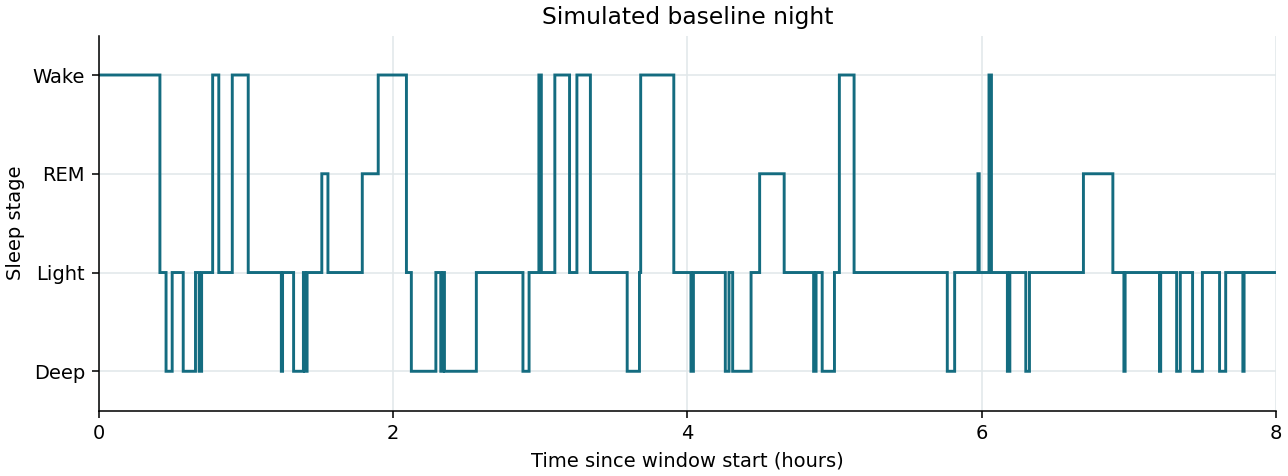

In [ ]:
import matplotlib.pyplot as plt

hypnogram_order = ["Deep", "Light", "REM", "Wake"]
hypnogram_positions = {stage: position for position, stage in enumerate(hypnogram_order)}
hypnogram_levels = [hypnogram_positions[stage] for stage in test_night_stages]
hypnogram_hours = np.arange(len(hypnogram_levels) + 1) * EPOCH_SECONDS / 3600

hypnogram_figure, hypnogram_ax = plt.subplots(figsize=(9.2, 3.4), layout="constrained")
hypnogram_ax.stairs(hypnogram_levels, hypnogram_hours, baseline=None, color="#146C80", linewidth=1.5)
hypnogram_ax.set(xlabel="Time since window start (hours)", ylabel="Sleep stage",
                 xlim=(0, 8), ylim=(-0.4, 3.4), title="Simulated baseline night")
hypnogram_ax.set_xticks([0, 2, 4, 6, 8])
hypnogram_ax.set_yticks(range(len(hypnogram_order)), hypnogram_order)
hypnogram_ax.set_axisbelow(True)
hypnogram_ax.grid(color="#E1E7EA", linewidth=0.8)
hypnogram_ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Experiments and results

[Parameter study or scenario comparison that answers your question. Report replications/seeds and confidence intervals, not single runs.]

In [ ]:
# REPLACE: your parameter sweep or scenario comparison

### Compare baseline with increased awakening probability

Apply a multiplier of at least 1 to the Light, Deep, and REM probabilities of moving to Wake. Proportionally rescale the remaining entries in each affected row. A multiplier of 1 gives the baseline, and the reciprocal of the largest sleep-to-Wake probability is the upper limit. The Wake row stays the same.

Each row shows the chance of moving to Wake in the next 30-second epoch. The change is the adjusted probability minus the original, in percentage points, calculated before rounding.

Each pair uses the same training initial distribution and eight-hour window. A master seed produces one child seed per pair. Two separate generators start from that child seed, one for the baseline matrix and one for the multiplier-2 matrix.

The 100-pair pilot summarizes Deep Sleep and REM minutes, multiplier-2 minus baseline differences, and two-sided paired t intervals. The 1.5 × IQR flags identify nights for inspection. All pairs are retained.

In [ ]:
def adjust_awakening_probabilities(transition_probabilities, multiplier):
    """Return a copy of the matrix with scaled sleep-to-Wake probabilities."""
    if not np.isfinite(multiplier) or multiplier < 1:
        raise ValueError("The awakening multiplier must be finite and at least 1")

    baseline = transition_probabilities.to_numpy()
    if not ((baseline >= 0) & (baseline <= 1)).all() or not np.allclose(baseline.sum(axis=1), 1):
        raise ValueError("The baseline matrix must have probabilities in [0, 1] and row sums of 1")

    sleep_stages = [stage for stage in STATES if stage != "Wake"]
    largest_wake_probability = transition_probabilities.loc[sleep_stages, "Wake"].max()
    if largest_wake_probability > 0:
        max_multiplier = 1.0 / largest_wake_probability
        if multiplier > max_multiplier:
            raise ValueError(f"The awakening multiplier must be between 1 and {max_multiplier:.17g}")

    adjusted = transition_probabilities.copy()
    if multiplier == 1:
        return adjusted

    for stage in sleep_stages:
        wake_probability = transition_probabilities.loc[stage, "Wake"]
        # Guard against floating-point overshoot at the validated upper limit.
        new_wake_probability = min(multiplier * wake_probability, 1.0)
        remaining_scale = (1 - new_wake_probability) / (1 - wake_probability)
        adjusted.loc[stage, "Wake"] = new_wake_probability
        adjusted.loc[stage, sleep_stages] = transition_probabilities.loc[stage, sleep_stages] * remaining_scale

    probabilities = adjusted.to_numpy()
    if not ((probabilities >= 0) & (probabilities <= 1)).all() or not np.allclose(probabilities.sum(axis=1), 1):
        raise ValueError("The adjusted matrix must have probabilities in [0, 1] and row sums of 1")
    return adjusted

In [ ]:
baseline_snapshot = training_transition_probabilities.copy()
baseline_adjusted = adjust_awakening_probabilities(training_transition_probabilities, 1)
pd.testing.assert_frame_equal(baseline_adjusted, baseline_snapshot, check_exact=True)
pd.testing.assert_frame_equal(training_transition_probabilities, baseline_snapshot, check_exact=True)
assert baseline_adjusted is not training_transition_probabilities, "Expected a separate matrix copy"
print("Multiplier 1 exactly matches the original matrix, and the input is unchanged.")

doubled_awakening = adjust_awakening_probabilities(training_transition_probabilities, 2)
sleep_stages = [stage for stage in STATES if stage != "Wake"]
np.testing.assert_allclose(
    doubled_awakening.loc[sleep_stages, "Wake"],
    2 * baseline_snapshot.loc[sleep_stages, "Wake"],
)
pd.testing.assert_series_equal(doubled_awakening.loc["Wake"], baseline_snapshot.loc["Wake"], check_exact=True)
np.testing.assert_allclose(doubled_awakening.sum(axis=1), 1.0)
print("Multiplier 2 doubles sleep-to-Wake probabilities, preserves the Wake row, and keeps row sums at 1.")

max_multiplier = 1 / baseline_snapshot.loc[sleep_stages, "Wake"].max()
invalid_multipliers = [
    (0.5, "at least 1"),
    (-1, "at least 1"),
    (np.nextafter(max_multiplier, np.inf), "between 1 and"),
    (np.nan, "multiplier must be finite"),
    (np.inf, "multiplier must be finite"),
    (-np.inf, "multiplier must be finite"),
]
for invalid_multiplier, expected_message in invalid_multipliers:
    try:
        adjust_awakening_probabilities(training_transition_probabilities, invalid_multiplier)
    except ValueError as error:
        assert expected_message in str(error), str(error)
    else:
        raise AssertionError(f"Expected ValueError for multiplier {invalid_multiplier}")
print("Invalid multiplier checks passed for out-of-range and non-finite values.")

original_wake = training_transition_probabilities.loc[sleep_stages, "Wake"]
doubled_wake = doubled_awakening.loc[sleep_stages, "Wake"]
awakening_comparison = pd.DataFrame({
    "Original (%)": 100 * original_wake,
    "Multiplier 2 (%)": 100 * doubled_wake,
    "Change (percentage points)": 100 * (doubled_wake - original_wake),
}).rename_axis("Current sleep stage")
display(awakening_comparison.round(2))

In [ ]:
def simulate_paired_nights(initial_probabilities, baseline_matrix, adjusted_matrix, pair_count, master_seed):
    """Return the baseline and adjusted night sequences in matching pair order."""
    baseline_nights = []
    adjusted_nights = []
    for child_seed in np.random.SeedSequence(master_seed).spawn(pair_count):
        baseline_rng = np.random.default_rng(child_seed)
        adjusted_rng = np.random.default_rng(child_seed)
        baseline_nights.append(simulate_night(initial_probabilities, baseline_matrix, baseline_rng))
        adjusted_nights.append(simulate_night(initial_probabilities, adjusted_matrix, adjusted_rng))
    return baseline_nights, adjusted_nights


pilot_pair_count = 100
pilot_master_seed = 4042
pilot_args = (
    initial_stage_probabilities, training_transition_probabilities, doubled_awakening,
    pilot_pair_count, pilot_master_seed,
)
baseline_pilot_nights, doubled_pilot_nights = simulate_paired_nights(*pilot_args)

for scenario, pilot_nights in (("Baseline", baseline_pilot_nights), ("Multiplier 2", doubled_pilot_nights)):
    assert len(pilot_nights) == pilot_pair_count, f"{scenario} must produce 100 nights"
    assert all(len(night) == 960 and set(night).issubset(STATES) for night in pilot_nights), (
        f"{scenario} contains a night with an incorrect length or invalid stage"
    )

assert simulate_paired_nights(*pilot_args) == (baseline_pilot_nights, doubled_pilot_nights), (
    "The same master seed must reproduce both scenarios"
)
print("Baseline and multiplier 2 each produced 100 valid nights of 960 epochs.")
print("Paired simulation check passed: the same master seed reproduced every stage in both scenarios.")

In [ ]:
pilot_scenarios = {"Baseline": baseline_pilot_nights, "Multiplier 2": doubled_pilot_nights}
deep_minutes_by_night = pd.DataFrame({
    scenario: [night.count("Deep") * EPOCH_SECONDS / 60 for night in nights]
    for scenario, nights in pilot_scenarios.items()
})
deep_mean_minutes = deep_minutes_by_night.mean()

for scenario, nights in pilot_scenarios.items():
    total_deep_epochs = sum(stage == "Deep" for night in nights for stage in night)
    mean_from_total = total_deep_epochs * EPOCH_SECONDS / (60 * pilot_pair_count)
    assert np.isclose(deep_mean_minutes[scenario], mean_from_total), f"{scenario} mean does not match the epoch total"

display(deep_mean_minutes.round(2).rename("Mean Deep Sleep (min)").to_frame().rename_axis("Scenario"))

rem_minutes_by_night = pd.DataFrame({
    scenario: [night.count("REM") * EPOCH_SECONDS / 60 for night in nights]
    for scenario, nights in pilot_scenarios.items()
})
rem_mean_minutes = rem_minutes_by_night.mean()

for scenario, nights in pilot_scenarios.items():
    total_rem_epochs = sum(stage == "REM" for night in nights for stage in night)
    mean_from_total = total_rem_epochs * EPOCH_SECONDS / (60 * pilot_pair_count)
    assert np.isclose(rem_mean_minutes[scenario], mean_from_total), f"{scenario} REM mean does not match the epoch total"

display(rem_mean_minutes.round(2).rename("Mean REM (min)").to_frame().rename_axis("Scenario"))

deep_paired_differences = deep_minutes_by_night["Multiplier 2"] - deep_minutes_by_night["Baseline"]
assert len(deep_paired_differences) == pilot_pair_count, "Expected one Deep Sleep difference per pair"
mean_deep_paired_difference = deep_paired_differences.mean()
deep_difference_of_means = deep_mean_minutes["Multiplier 2"] - deep_mean_minutes["Baseline"]
assert np.isclose(mean_deep_paired_difference, deep_difference_of_means), (
    "Mean paired Deep Sleep difference must match the difference between scenario means"
)
print(f"Mean paired Deep Sleep difference: {mean_deep_paired_difference:.3f} minutes.")
print(f"Difference between scenario means: {deep_difference_of_means:.3f} minutes.")

rem_paired_differences = rem_minutes_by_night["Multiplier 2"] - rem_minutes_by_night["Baseline"]
assert len(rem_paired_differences) == pilot_pair_count, "Expected one REM difference per pair"
mean_rem_paired_difference = rem_paired_differences.mean()
rem_difference_of_means = rem_mean_minutes["Multiplier 2"] - rem_mean_minutes["Baseline"]
assert np.isclose(mean_rem_paired_difference, rem_difference_of_means), (
    "Mean paired REM difference must match the difference between scenario means"
)
print(f"Mean paired REM difference: {mean_rem_paired_difference:.3f} minutes.")
print(f"Difference between scenario means: {rem_difference_of_means:.3f} minutes.")

In [ ]:
from scipy.stats import t, ttest_1samp

deep_pair_count = len(deep_paired_differences)
deep_sample_sd = deep_paired_differences.std(ddof=1)
deep_standard_error = deep_sample_sd / np.sqrt(deep_pair_count)
deep_t_critical = t.ppf(0.975, df=deep_pair_count - 1)
deep_margin = deep_t_critical * deep_standard_error
deep_ci_lower = mean_deep_paired_difference - deep_margin
deep_ci_upper = mean_deep_paired_difference + deep_margin

deep_reference_ci = ttest_1samp(deep_paired_differences, popmean=0).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose([deep_ci_lower, deep_ci_upper], [deep_reference_ci.low, deep_reference_ci.high])
print(f"Deep Sleep 95% confidence interval: [{deep_ci_lower:.3f}, {deep_ci_upper:.3f}] minutes.")
print("Both limits match the one-sample t-test interval on the paired differences.")

rem_pair_count = len(rem_paired_differences)
rem_sample_sd = rem_paired_differences.std(ddof=1)
rem_standard_error = rem_sample_sd / np.sqrt(rem_pair_count)
rem_t_critical = t.ppf(0.975, df=rem_pair_count - 1)
rem_margin = rem_t_critical * rem_standard_error
rem_ci_lower = mean_rem_paired_difference - rem_margin
rem_ci_upper = mean_rem_paired_difference + rem_margin

rem_reference_ci = ttest_1samp(rem_paired_differences, popmean=0).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose([rem_ci_lower, rem_ci_upper], [rem_reference_ci.low, rem_reference_ci.high])
print(f"REM 95% confidence interval: [{rem_ci_lower:.3f}, {rem_ci_upper:.3f}] minutes.")
print("Both limits match the one-sample t-test interval on the paired differences.")

In [ ]:
deep_q1, deep_q3 = deep_paired_differences.quantile([0.25, 0.75]).to_numpy()
deep_iqr = deep_q3 - deep_q1
deep_iqr_lower = deep_q1 - 1.5 * deep_iqr
deep_iqr_upper = deep_q3 + 1.5 * deep_iqr
deep_flagged_positions = np.flatnonzero(
    (deep_paired_differences < deep_iqr_lower) | (deep_paired_differences > deep_iqr_upper)
)

display(pd.DataFrame([{"Q1 (min)": deep_q1, "Q3 (min)": deep_q3, "IQR (min)": deep_iqr,
                       "Lower limit (min)": deep_iqr_lower, "Upper limit (min)": deep_iqr_upper,
                       "Flagged pairs": len(deep_flagged_positions)}]).round(4))

if deep_flagged_positions.size:
    deep_flagged_pairs = deep_minutes_by_night.iloc[deep_flagged_positions].copy()
    deep_flagged_pairs.columns = ["Baseline (min)", "Multiplier 2 (min)"]
    deep_flagged_pairs["Difference (min)"] = deep_paired_differences.iloc[deep_flagged_positions].to_numpy()
    deep_flagged_pairs.index = pd.Index(deep_flagged_positions + 1, name="Pair number")
    display(deep_flagged_pairs)

rem_q1, rem_q3 = rem_paired_differences.quantile([0.25, 0.75]).to_numpy()
rem_iqr = rem_q3 - rem_q1
rem_iqr_lower = rem_q1 - 1.5 * rem_iqr
rem_iqr_upper = rem_q3 + 1.5 * rem_iqr
rem_flagged_positions = np.flatnonzero(
    (rem_paired_differences < rem_iqr_lower) | (rem_paired_differences > rem_iqr_upper)
)

display(pd.DataFrame([{
    "Q1 (min)": rem_q1,
    "Q3 (min)": rem_q3,
    "IQR (min)": rem_iqr,
    "Lower limit (min)": rem_iqr_lower,
    "Upper limit (min)": rem_iqr_upper,
    "Flagged pairs": len(rem_flagged_positions),
}]).round(4))

if rem_flagged_positions.size:
    rem_flagged_pairs = rem_minutes_by_night.iloc[rem_flagged_positions].copy()
    rem_flagged_pairs.columns = ["Baseline (min)", "Multiplier 2 (min)"]
    rem_flagged_pairs["Difference (min)"] = rem_paired_differences.iloc[rem_flagged_positions].to_numpy()
    rem_flagged_pairs.index = pd.Index(rem_flagged_positions + 1, name="Pair number")
    display(rem_flagged_pairs)

### Final Monte Carlo experiment with 10,000 paired nights

The baseline and multiplier-2 scenarios use the same initial distribution and 960 epochs per night. Assign child seeds from master seed 4042 before batching. Store the Deep Sleep and REM durations and awakening counts in pair order. The paired difference is multiplier 2 minus baseline.

Pass the same initial probabilities and ordered child seeds to both scenarios. The same row in each returned array belongs to the same pair.

Count a transition into Wake only when the preceding epoch is Light, Deep, or REM. An initial Wake epoch and consecutive Wake epochs contribute zero.

The final t intervals use the sample standard deviations of the paired differences and 9,999 degrees of freedom. The summary table reports the paired intervals, and the two-panel figure shows the scenario means.

In [ ]:
def simulate_pairs_batched(initial_probabilities, baseline_matrix, adjusted_matrix, child_seeds):
    """Return baseline and adjusted night arrays in matching pair order."""
    baseline_nights = simulate_nights_batched(initial_probabilities, baseline_matrix, child_seeds)
    adjusted_nights = simulate_nights_batched(initial_probabilities, adjusted_matrix, child_seeds)
    return baseline_nights, adjusted_nights


small_batch_baseline, small_batch_doubled = simulate_pairs_batched(
    initial_stage_probabilities, training_transition_probabilities, doubled_awakening, small_batch_seeds
)
assert small_batch_baseline.shape == small_batch_doubled.shape == (4, 960)

first_baseline, second_baseline = simulate_pairs_batched(
    initial_stage_probabilities, training_transition_probabilities, training_transition_probabilities, small_batch_seeds
)
np.testing.assert_array_equal(first_baseline, second_baseline)
print("Four-pair batch check passed. Identical matrices produced identical sequences.")

def count_awakenings(stages):
    """Count transitions from a sleep stage into Wake."""
    stages = np.asarray(stages)
    previous_is_sleep = np.isin(stages[:-1], ("Light", "Deep", "REM"))
    next_is_wake = stages[1:] == "Wake"
    return np.count_nonzero(previous_is_sleep & next_is_wake)


awakening_example = ["Wake", "Light", "Wake", "Wake", "REM", "Wake"]
assert count_awakenings(awakening_example) == 2
assert count_awakenings(["Wake", "Light"]) == 0
print("Awakening checks passed. The example contains two awakenings, and starting in Wake contributes zero.")

In [ ]:
final_pair_count = 10_000
final_batch_size = 500
final_master_seed = 4042
final_stages = ("Deep", "REM")


def run_final_paired_metrics(master_seed):
    child_seeds = np.random.SeedSequence(master_seed).spawn(final_pair_count)
    baseline_minutes = np.empty((final_pair_count, len(final_stages)))
    doubled_minutes = np.empty_like(baseline_minutes)
    baseline_awakenings = np.empty(final_pair_count, dtype=np.int64)
    doubled_awakenings = np.empty_like(baseline_awakenings)
    for start in range(0, final_pair_count, final_batch_size):
        batch_seeds = child_seeds[start:start + final_batch_size]
        stop = start + len(batch_seeds)
        baseline_nights, doubled_nights = simulate_pairs_batched(
            initial_stage_probabilities, training_transition_probabilities, doubled_awakening, batch_seeds
        )
        assert baseline_nights.shape == doubled_nights.shape == (len(batch_seeds), 960)
        for column, stage in enumerate(final_stages):
            baseline_minutes[start:stop, column] = np.count_nonzero(baseline_nights == stage, axis=1) * EPOCH_SECONDS / 60
            doubled_minutes[start:stop, column] = np.count_nonzero(doubled_nights == stage, axis=1) * EPOCH_SECONDS / 60
        baseline_awakenings[start:stop] = np.fromiter(
            (count_awakenings(night) for night in baseline_nights), dtype=np.int64, count=len(batch_seeds)
        )
        doubled_awakenings[start:stop] = np.fromiter(
            (count_awakenings(night) for night in doubled_nights), dtype=np.int64, count=len(batch_seeds)
        )
    return baseline_minutes, doubled_minutes, baseline_awakenings, doubled_awakenings


(final_baseline_minutes, final_doubled_minutes,
 final_baseline_awakenings, final_doubled_awakenings) = run_final_paired_metrics(final_master_seed)
assert len(final_baseline_minutes) == len(final_doubled_minutes) == 10_000
(replay_baseline_minutes, replay_doubled_minutes,
 replay_baseline_awakenings, replay_doubled_awakenings) = run_final_paired_metrics(final_master_seed)
np.testing.assert_array_equal(final_baseline_minutes, replay_baseline_minutes)
np.testing.assert_array_equal(final_doubled_minutes, replay_doubled_minutes)
np.testing.assert_array_equal(final_baseline_awakenings, replay_baseline_awakenings)
np.testing.assert_array_equal(final_doubled_awakenings, replay_doubled_awakenings)

final_paired_differences = final_doubled_minutes - final_baseline_minutes
final_results = pd.DataFrame({
    "Baseline mean (min)": final_baseline_minutes.mean(axis=0),
    "Multiplier 2 mean (min)": final_doubled_minutes.mean(axis=0),
    "Mean paired difference (min)": final_paired_differences.mean(axis=0),
}, index=pd.Index(["Deep Sleep", "REM"], name="Sleep stage"))
np.testing.assert_allclose(
    final_results["Mean paired difference (min)"],
    final_results["Multiplier 2 mean (min)"] - final_results["Baseline mean (min)"],
)
display(final_results.round(3))
final_mean_awakenings = pd.DataFrame(
    {"Mean awakenings per night": [final_baseline_awakenings.mean(), final_doubled_awakenings.mean()]},
    index=pd.Index(["Baseline", "Multiplier 2"], name="Scenario"),
)
display(final_mean_awakenings.round(3))
print("Verified 10,000 nights per scenario and exact reproduction of every stored duration and count with seed 4042.")

,Baseline mean (min),Multiplier 2 mean (min),Mean paired difference (min)
Sleep stage,,,
Deep Sleep,62.234,53.660,-8.574
REM,83.824,62.996,-20.829


,Mean awakenings per night
Scenario,
Baseline,10.147
Multiplier 2,17.498


Verified 10,000 nights per scenario and exact reproduction of every stored duration and count with seed 4042.


In [ ]:
final_deep_differences = final_paired_differences[:, final_stages.index("Deep")]
final_deep_pair_count = len(final_deep_differences)
final_deep_mean = final_deep_differences.mean()
final_deep_sample_sd = final_deep_differences.std(ddof=1)
final_deep_standard_error = final_deep_sample_sd / np.sqrt(final_deep_pair_count)
final_deep_t_critical = t.ppf(0.975, df=final_deep_pair_count - 1)
final_deep_margin = final_deep_t_critical * final_deep_standard_error
final_deep_ci_lower = final_deep_mean - final_deep_margin
final_deep_ci_upper = final_deep_mean + final_deep_margin

final_deep_reference_ci = ttest_1samp(final_deep_differences, popmean=0).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose(
    [final_deep_ci_lower, final_deep_ci_upper],
    [final_deep_reference_ci.low, final_deep_reference_ci.high],
)
print(f"Final Deep Sleep 95% confidence interval: [{final_deep_ci_lower:.3f}, {final_deep_ci_upper:.3f}] minutes.")
print("Both limits match SciPy's one-sample t-test interval on the paired differences.")

final_rem_differences = final_paired_differences[:, final_stages.index("REM")]
final_rem_pair_count = len(final_rem_differences)
final_rem_mean = final_rem_differences.mean()
final_rem_sample_sd = final_rem_differences.std(ddof=1)
final_rem_standard_error = final_rem_sample_sd / np.sqrt(final_rem_pair_count)
final_rem_t_critical = t.ppf(0.975, df=final_rem_pair_count - 1)
final_rem_margin = final_rem_t_critical * final_rem_standard_error
final_rem_ci_lower = final_rem_mean - final_rem_margin
final_rem_ci_upper = final_rem_mean + final_rem_margin

final_rem_reference_ci = ttest_1samp(final_rem_differences, popmean=0).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose(
    [final_rem_ci_lower, final_rem_ci_upper],
    [final_rem_reference_ci.low, final_rem_reference_ci.high],
)
print(f"Final REM 95% confidence interval: [{final_rem_ci_lower:.3f}, {final_rem_ci_upper:.3f}] minutes.")
print("Both limits match SciPy's one-sample t-test interval on the paired differences.")

final_awakening_differences = final_doubled_awakenings - final_baseline_awakenings
final_awakening_pair_count = len(final_awakening_differences)
final_awakening_mean = final_awakening_differences.mean()
final_awakening_sample_sd = final_awakening_differences.std(ddof=1)
final_awakening_standard_error = final_awakening_sample_sd / np.sqrt(final_awakening_pair_count)
final_awakening_t_critical = t.ppf(0.975, df=final_awakening_pair_count - 1)
final_awakening_margin = final_awakening_t_critical * final_awakening_standard_error
final_awakening_ci_lower = final_awakening_mean - final_awakening_margin
final_awakening_ci_upper = final_awakening_mean + final_awakening_margin

final_awakening_reference_ci = ttest_1samp(
    final_awakening_differences, popmean=0
).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose(
    [final_awakening_ci_lower, final_awakening_ci_upper],
    [final_awakening_reference_ci.low, final_awakening_reference_ci.high],
)
print(f"Mean paired awakening difference: {final_awakening_mean:.4f} awakenings per night.")
print(f"95% confidence interval: [{final_awakening_ci_lower:.4f}, {final_awakening_ci_upper:.4f}] awakenings per night.")
print("Both limits match SciPy's one-sample t-test interval on the paired differences.")

Final Deep Sleep 95% confidence interval: [-8.783, -8.365] minutes.
Both limits match SciPy's one-sample t-test interval on the paired differences.


Final REM 95% confidence interval: [-21.192, -20.465] minutes.
Both limits match SciPy's one-sample t-test interval on the paired differences.


Mean paired awakening difference: 7.3511 awakenings per night.
95% confidence interval: [7.3000, 7.4022] awakenings per night.
Both limits match SciPy's one-sample t-test interval on the paired differences.


,Baseline mean,Multiplier 2 mean,Mean paired difference,95% CI for mean difference
Outcome,,,,
Deep Sleep (min),62.234,53.660,-8.574,"[-8.783, -8.365]"
REM (min),83.824,62.996,-20.829,"[-21.192, -20.465]"
Awakenings per night,10.147,17.498,7.351,"[7.300, 7.402]"


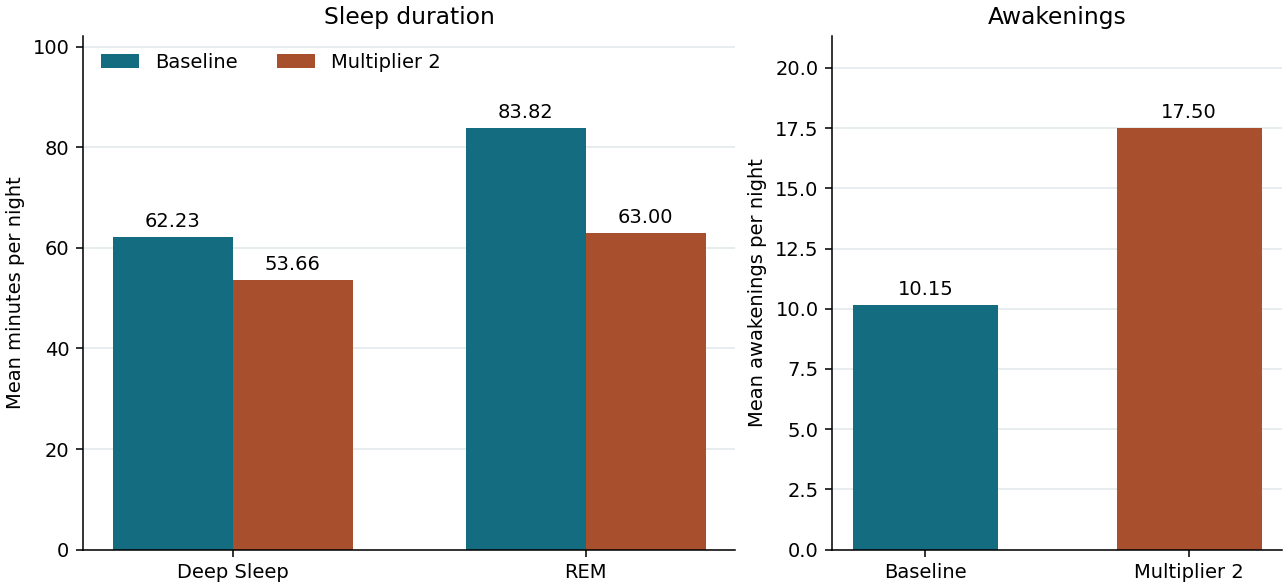

In [ ]:
final_summary = final_results.rename(
    index={"Deep Sleep": "Deep Sleep (min)", "REM": "REM (min)"},
    columns={
        "Baseline mean (min)": "Baseline mean",
        "Multiplier 2 mean (min)": "Multiplier 2 mean",
        "Mean paired difference (min)": "Mean paired difference",
    },
).rename_axis("Outcome")
final_summary.loc["Awakenings per night"] = [
    final_mean_awakenings.loc["Baseline", "Mean awakenings per night"],
    final_mean_awakenings.loc["Multiplier 2", "Mean awakenings per night"],
    final_awakening_mean,
]
final_summary["95% CI for mean difference"] = [
    f"[{final_deep_ci_lower:.3f}, {final_deep_ci_upper:.3f}]",
    f"[{final_rem_ci_lower:.3f}, {final_rem_ci_upper:.3f}]",
    f"[{final_awakening_ci_lower:.3f}, {final_awakening_ci_upper:.3f}]",
]
display(final_summary.round(3))

import matplotlib.pyplot as plt

scenarios = ("Baseline", "Multiplier 2")
colors = ("#146C80", "#A8502D")
duration_means = final_summary.loc[["Deep Sleep (min)", "REM (min)"],
                                   ["Baseline mean", "Multiplier 2 mean"]]
awakening_means = final_mean_awakenings.loc[list(scenarios), "Mean awakenings per night"]

fig, (duration_ax, awakening_ax) = plt.subplots(
    1, 2, figsize=(9.2, 4.2), gridspec_kw={"width_ratios": [1.45, 1]}, layout="constrained"
)
positions = np.arange(len(duration_means))
bar_width = 0.34
for i, (scenario, color) in enumerate(zip(scenarios, colors)):
    bars = duration_ax.bar(positions + (i - 0.5) * bar_width, duration_means.iloc[:, i],
                           width=bar_width, color=color, label=scenario)
    duration_ax.bar_label(bars, fmt="%.2f", padding=3)
duration_ax.set_xticks(positions, ["Deep Sleep", "REM"])
duration_ax.set_title("Sleep duration")
duration_ax.set_ylabel("Mean minutes per night")
duration_ax.set_ylim(0, duration_means.to_numpy().max() * 1.22)
duration_ax.legend(loc="upper left", frameon=False, ncol=2)

awakening_bars = awakening_ax.bar(scenarios, awakening_means, color=colors, width=0.55)
awakening_ax.bar_label(awakening_bars, fmt="%.2f", padding=3)
awakening_ax.set_title("Awakenings")
awakening_ax.set_ylabel("Mean awakenings per night")
awakening_ax.set_ylim(0, awakening_means.max() * 1.22)

for ax in (duration_ax, awakening_ax):
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E1E7EA", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Held-out transition probabilities

Divide each held-out row by its total transition count. Rows show the current stage and columns show the next stage. A row with zero transitions is unavailable because there are no observed transitions from that stage.

Differences are in percentage points. A positive value means the transition was more common in the held-out recordings. The largest gap is selected before rounding.

In [ ]:
held_out_counts = split_counts["held-out"].loc[list(STATES), list(STATES)]
held_out_row_totals = held_out_counts.sum(axis=1)
held_out_available_rows = held_out_row_totals.gt(0)
held_out_transition_probabilities = held_out_counts.div(
    held_out_row_totals.where(held_out_available_rows), axis="index"
)
np.testing.assert_allclose(
    held_out_transition_probabilities.loc[held_out_available_rows].sum(axis=1), 1.0
)
display(held_out_row_totals.rename("Held-out transition count").to_frame().rename_axis("Current stage"))
held_out_display = held_out_transition_probabilities.round(6).astype(object)
display(held_out_display.where(held_out_display.notna(), "Unavailable").rename_axis("Current stage"))
print(f"All {held_out_available_rows.sum()} available held-out rows sum to 1 before rounding.")

transition_differences_pp = 100 * (held_out_transition_probabilities - training_transition_probabilities)
transition_differences_pp = transition_differences_pp.loc[list(STATES), list(STATES)]
difference_display = transition_differences_pp.apply(
    lambda column: column.map(lambda value: f"{value:.2f}" if pd.notna(value) else "Unavailable")
)
display(difference_display.rename_axis("Current stage"))

absolute_differences = np.abs(transition_differences_pp.to_numpy())
if np.isfinite(absolute_differences).any():
    row, column = np.unravel_index(np.nanargmax(absolute_differences), absolute_differences.shape)
    largest_difference = transition_differences_pp.iloc[row, column]
    print(f"Largest absolute difference: {STATES[row]} to {STATES[column]}, "
          f"{abs(largest_difference):.2f} percentage points (held-out minus training: {largest_difference:+.2f}).")
else:
    print("No held-out rows are available for comparison.")

,Held-out transition count
Current stage,
Wake,1165
Light,3558
Deep,979
REM,1199


,Wake,Light,Deep,REM
Current stage,,,,
Wake,0.920172,0.070386,0.0,0.009442
Light,0.018269,0.918775,0.040753,0.022203
Deep,0.00715,0.139939,0.85189,0.001021
REM,0.017515,0.057548,0.000834,0.924103


All 4 available held-out rows sum to 1 before rounding.


,Wake,Light,Deep,REM
Current stage,,,,
Wake,-1.55,0.78,-0.03,0.81
Light,0.27,-1.00,0.31,0.42
Deep,0.33,-0.50,0.11,0.06
REM,0.62,1.50,0.08,-2.21


Largest absolute difference: REM to REM, 2.21 percentage points (held-out minus training: -2.21).


The largest difference was REM → REM. The chance of staying in REM for another 30-second epoch was 2.21 percentage points lower in the held-out recordings than in training. Transitions into Wake were more common in the held-out recordings from all three sleep stages: 0.27 percentage points higher from Light, 0.33 from Deep, and 0.62 from REM.

The fitted matrix therefore estimates more persistent REM and lower one-step awakening probabilities than observed in the held-out recordings. This comparison checks individual transitions. How well the model reproduces whole-night stage durations and awakening counts remains a separate question.

### Rigorous Verification

An independent check propagates probability mass through the fitted four-state Markov chain. Let $q_t$ be the row vector of stage probabilities at epoch $t$, $\pi$ the fitted initial distribution, and $P$ the transition matrix for the selected scenario. For $T=960$ epochs, $q_0=\pi$ and $q_{t+1}=q_tP$. With $\Delta=0.5$ minutes per epoch, the expected duration in stage $j$ and expected awakening count are

$$
\mathbb E[Y_j] = \Delta\sum_{t=0}^{T-1}q_t(j), \qquad
\mathbb E[A] = \sum_{t=0}^{T-2}\sum_{i\in\{L,D,R\}}q_t(i)P_{iW}.
$$

Here $L,D,R,W$ denote Light, Deep, REM, and Wake. The awakening sum covers the $T-1$ transitions. Starting in Wake and staying in Wake contribute zero. The recurrence uses neither random draws nor a simulated path.

The check compares both scenario means and the intervention-minus-baseline differences with the existing 10,000 pairs. It estimates each standard error from the corresponding night outcomes or within-pair differences. The table shows pointwise 95% t intervals. A separate Bonferroni-adjusted t threshold checks the nine discrepancies together at an approximate 95% family-wise confidence level.

For convergence, estimate **baseline REM minutes** from independent groups of $N$ nights. Each group mean is compared with the deterministic expectation $\mu$. Over $R$ independent repetitions at each $N$, compute

$$
\operatorname{RMSE}(N) = \sqrt{\frac{1}{R}\sum_{r=1}^{R}\left(\widehat\mu_{N,r}-\mu\right)^2}.
$$

For an unbiased mean of independent nights with finite per-night variance $\sigma^2$, the theoretical RMSE is $\sigma/\sqrt{N}$. On a log-log plot this implies a slope of $-1/2$. The plot uses the original baseline REM sample standard deviation to set the height of the reference line. It estimates the measured slope by least squares on the log sample sizes and log RMSEs.

In [26]:
def expected_night_metrics(initial, transition, epoch_count, epoch_minutes):
    """Propagate stage probabilities and accumulate expected rewards."""
    stage_order = list(STATES)
    distribution = initial.loc[stage_order].to_numpy(dtype=float)
    matrix = transition.loc[stage_order, stage_order].to_numpy(dtype=float)
    wake = stage_order.index("Wake")
    sleep_rows = [stage_order.index(stage) for stage in ("Light", "Deep", "REM")]
    expected_epochs = distribution.copy()
    expected_awakenings = 0.0

    for _ in range(epoch_count - 1):
        expected_awakenings += distribution[sleep_rows] @ matrix[sleep_rows, wake]
        distribution = distribution @ matrix
        expected_epochs += distribution

    np.testing.assert_allclose(distribution.sum(), 1, rtol=0, atol=1e-10)
    np.testing.assert_allclose(expected_epochs.sum(), epoch_count, rtol=0, atol=1e-8)
    return pd.Series(expected_epochs * epoch_minutes, index=stage_order), expected_awakenings


x2_epoch_count = 8 * 60 * 60 // EPOCH_SECONDS
x2_epoch_minutes = EPOCH_SECONDS / 60
x2_stage_order = list(STATES)
x2_wake = x2_stage_order.index("Wake")
x2_light = x2_stage_order.index("Light")
x2_identity = pd.DataFrame(np.eye(len(STATES)), index=STATES, columns=STATES)
x2_minutes, x2_awakenings = expected_night_metrics(
    initial_stage_probabilities, x2_identity, x2_epoch_count, x2_epoch_minutes
)
np.testing.assert_allclose(x2_minutes, [480, 0, 0, 0])
assert x2_awakenings == 0, "A night that stays in Wake has no awakenings"

x2_alternating = x2_identity.copy()
x2_alternating.iloc[[x2_wake, x2_light]] = x2_identity.iloc[[x2_light, x2_wake]].to_numpy()
x2_minutes, x2_awakenings = expected_night_metrics(
    initial_stage_probabilities, x2_alternating, 5, x2_epoch_minutes
)
np.testing.assert_allclose(x2_minutes, [1.5, 1.0, 0, 0])
assert x2_awakenings == 2, "Wake → Light → Wake → Light → Wake has two awakenings"

x2_exact_baseline = expected_night_metrics(
    initial_stage_probabilities, training_transition_probabilities, x2_epoch_count, x2_epoch_minutes
)
x2_exact_doubled = expected_night_metrics(
    initial_stage_probabilities, doubled_awakening, x2_epoch_count, x2_epoch_minutes
)
x2_baseline_truth = np.r_[x2_exact_baseline[0].loc[list(final_stages)], x2_exact_baseline[1]]
x2_doubled_truth = np.r_[x2_exact_doubled[0].loc[list(final_stages)], x2_exact_doubled[1]]
x2_baseline_samples = np.column_stack((final_baseline_minutes, final_baseline_awakenings))
x2_doubled_samples = np.column_stack((final_doubled_minutes, final_doubled_awakenings))
x2_comparisons = (
    ("Baseline", x2_baseline_truth, x2_baseline_samples),
    ("Multiplier 2", x2_doubled_truth, x2_doubled_samples),
    ("Multiplier 2 − baseline", x2_doubled_truth - x2_baseline_truth, x2_doubled_samples - x2_baseline_samples),
)
x2_rows = []
x2_outcomes = ("Deep Sleep (min)", "REM (min)", "Awakenings/night")
x2_pointwise_t = t.ppf(0.975, df=final_pair_count - 1)
x2_joint_t = t.ppf(1 - 0.05 / (2 * len(x2_comparisons) * len(x2_outcomes)), df=final_pair_count - 1)

for scenario, exact, samples in x2_comparisons:
    mc_mean = samples.mean(axis=0)
    mc_se = samples.std(axis=0, ddof=1) / np.sqrt(len(samples))
    error = mc_mean - exact
    for i, outcome in enumerate(x2_outcomes):
        x2_rows.append({
            "Scenario": scenario,
            "Outcome": outcome,
            "Deterministic": exact[i],
            "Monte Carlo": mc_mean[i],
            "MC − deterministic": error[i],
            "MC standard error": mc_se[i],
            "95% CI lower": mc_mean[i] - x2_pointwise_t * mc_se[i],
            "95% CI upper": mc_mean[i] + x2_pointwise_t * mc_se[i],
            "|Error| / SE": abs(error[i]) / mc_se[i],
        })

x2_verification = pd.DataFrame(x2_rows).set_index(["Scenario", "Outcome"])
display(x2_verification.round(4))
x2_max_standardised_error = x2_verification["|Error| / SE"].max()
assert x2_max_standardised_error <= x2_joint_t, "An estimate exceeds the joint Monte Carlo tolerance"
x2_inside_pointwise = x2_verification["|Error| / SE"].le(x2_pointwise_t).sum()
print(f"Deterministic edge cases passed. {x2_inside_pointwise}/9 expectations lie within the pointwise 95% intervals.")
print(f"Largest discrepancy: {x2_max_standardised_error:.3f} standard errors (joint threshold {x2_joint_t:.3f}).")

Deterministic  Monte Carlo  \
Scenario                Outcome                                        
Baseline                Deep Sleep (min)        62.3903      62.2340   
                        REM (min)               84.0651      83.8244   
                        Awakenings/night        10.1011      10.1472   
Multiplier 2            Deep Sleep (min)        53.7751      53.6601   
                        REM (min)               63.0528      62.9957   
                        Awakenings/night        17.4601      17.4983   
Multiplier 2 − baseline Deep Sleep (min)        -8.6152      -8.5739   
                        REM (min)              -21.0123     -20.8287   
                        Awakenings/night         7.3590       7.3511   

                                          MC − deterministic  \
Scenario                Outcome                                
Baseline                Deep Sleep (min)             -0.1563   
                        REM (min)                    -0.2407   
                        Awakenings/night              0.0461   
Multiplier 2            Deep Sleep (min)             -0.1150   
                        REM (min)                    -0.0571   
                        Awakenings/night              0.0382   
Multiplier 2 − baseline Deep Sleep (min)              0.0413   
                        REM (min)                     0.1836   
                        Awakenings/night             -0.0079   

                                          MC standard error  95% CI lower  \
Scenario                Outcome                                             
Baseline                Deep Sleep (min)             0.1820       61.8772   
                        REM (min)                    0.3164       83.2042   
                        Awakenings/night             0.0273       10.0938   
Multiplier 2            Deep Sleep (min)             0.1700       53.3269   
                        REM (min)                    0.2652       62.4758   
                        Awakenings/night             0.0325       17.4347   
Multiplier 2 − baseline Deep Sleep (min)             0.1065       -8.7827   
                        REM (min)                    0.1855      -21.1923   
                        Awakenings/night             0.0261        7.3000   

                                          95% CI upper  |Error| / SE  
Scenario                Outcome                                       
Baseline                Deep Sleep (min)       62.5908        0.8585  
                        REM (min)              84.4446        0.7608  
                        Awakenings/night       10.2006        1.6927  
Multiplier 2            Deep Sleep (min)       53.9933        0.6765  
                        REM (min)              63.5156        0.2152  
                        Awakenings/night       17.5619        1.1773  
Multiplier 2 − baseline Deep Sleep (min)       -8.3651        0.3875  
                        REM (min)             -20.4651        0.9901  
                        Awakenings/night        7.4022        0.3033

Deterministic edge cases passed. 9/9 expectations lie within the pointwise 95% intervals.
Largest discrepancy: 1.693 standard errors (joint threshold 2.774).


,Measured RMSE (min),Reference SD / √N (min)
Nights per repetition,,
16,7.9746,7.9104
32,6.7112,5.5935
64,4.1307,3.9552
128,2.4448,2.7967
256,2.1141,1.9776


Log-log slope: -0.5288. Theoretical slope: −0.5000.
32 independent repetitions per size, 15,872 nights total.


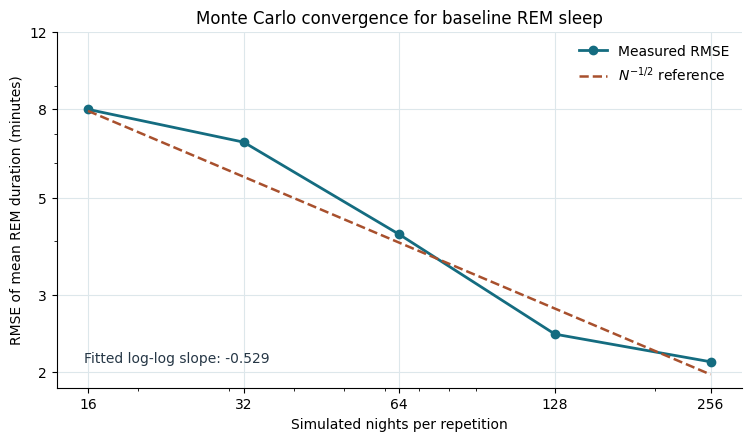

In [27]:
def rem_convergence_errors(sample_sizes, repetitions, master_seed, reference_minutes):
    """Use disjoint child streams for every sample size and repetition."""
    streams = iter(np.random.SeedSequence(master_seed).spawn(repetitions * sum(sample_sizes)))
    errors = np.empty((len(sample_sizes), repetitions))
    for row, sample_size in enumerate(sample_sizes):
        for repetition in range(repetitions):
            night_seeds = [next(streams) for _ in range(sample_size)]
            stage_paths = simulate_nights_batched(
                initial_stage_probabilities, training_transition_probabilities, night_seeds
            )
            assert stage_paths.shape == (sample_size, x2_epoch_count)
            mean_rem_minutes = np.count_nonzero(stage_paths == "REM") * x2_epoch_minutes / sample_size
            errors[row, repetition] = mean_rem_minutes - reference_minutes
    return errors


x2_sample_sizes = (16, 32, 64, 128, 256)
x2_repetitions = 32
x2_convergence_seed = 54042
x2_rem_expectation = x2_exact_baseline[0].loc["REM"]
x2_errors = rem_convergence_errors(x2_sample_sizes, x2_repetitions, x2_convergence_seed, x2_rem_expectation)
x2_rmse = np.sqrt(np.mean(x2_errors**2, axis=1))
assert np.isfinite(x2_rmse).all() and (x2_rmse > 0).all()
assert x2_rmse[-1] < x2_rmse[0], "The largest sample should have lower measured RMSE than the smallest"
x2_slope = np.polyfit(np.log(x2_sample_sizes), np.log(x2_rmse), deg=1)[0]
x2_reference_rmse = final_baseline_minutes[:, final_stages.index("REM")].std(ddof=1) / np.sqrt(x2_sample_sizes)
x2_convergence = pd.DataFrame({
    "Nights per repetition": x2_sample_sizes,
    "Measured RMSE (min)": x2_rmse,
    "Reference SD / √N (min)": x2_reference_rmse,
}).set_index("Nights per repetition")
display(x2_convergence.round(4))
print(f"Log-log slope: {x2_slope:.4f}. Theoretical slope: −0.5000.")
print(f"{x2_repetitions} independent repetitions per size, {x2_repetitions * sum(x2_sample_sizes):,} nights total.")

x2_figure, x2_ax = plt.subplots(figsize=(7.4, 4.3), layout="constrained")
x2_ax.loglog(x2_sample_sizes, x2_rmse, "o-", color="#146C80", lw=2, ms=6, label="Measured RMSE")
x2_ax.loglog(x2_sample_sizes, x2_reference_rmse, "--", color="#A8502D", lw=1.8, label=r"$N^{-1/2}$ reference")
x2_ax.set_xticks(x2_sample_sizes, [str(size) for size in x2_sample_sizes])
x2_ax.set_yticks([2, 3, 5, 8, 12], ["2", "3", "5", "8", "12"])
x2_ax.tick_params(which="minor", labelbottom=False, labelleft=False)
x2_ax.set(
    xlabel="Simulated nights per repetition",
    ylabel="RMSE of mean REM duration (minutes)",
    title="Monte Carlo convergence for baseline REM sleep",
)
x2_ax.text(0.04, 0.07, f"Fitted log-log slope: {x2_slope:.3f}", transform=x2_ax.transAxes, color="#263746")
x2_ax.grid(which="major", color="#DDE7EB", lw=0.8)
x2_ax.set_axisbelow(True)
x2_ax.spines[["top", "right"]].set_visible(False)
x2_ax.legend(frameon=False, loc="upper right")
plt.show()

The joint check assesses the size of the differences relative to sampling uncertainty. The comparison targets the finite eight-hour model, with Wake at the start of the observation window. Agreement verifies the simulation against its own stochastic model. How well that model represents observed nights is a separate question addressed only in part by the held-out comparison.

The measured slope estimates the convergence rate for baseline REM duration. Sampling variation across the 32 repetitions at each size can move the slope away from −0.5. The experiment does not estimate convergence for every outcome or uncertainty in the fitted transition probabilities.

### Sensitivity and Uncertainty Analysis

This sweep varies the awakening multiplier across **1, 1.25, 1.5, 2, 2.5, and 3**. It holds the fitted model, initial distribution, and eight-hour window fixed. Each setting uses 2,000 nights. For each night index, all six settings use the same uniform draws from one child stream of NumPy master seed 4042. Night indices have distinct child streams.

The sweep reuses the first 2,000 recorded outcomes at multipliers 1 and 2 from the existing final experiment. It simulates the four other settings with those same child streams, adding 8,000 nights. This avoids fitting the model or simulating the baseline again for every comparison. The sweep is a matched subset, so its estimates for multipliers 1 and 2 can differ from the original 10,000-pair estimates.

For each outcome and multiplier, the pointwise 95% Student's t interval is the sample mean plus or minus $t_{0.975,N-1}s/\sqrt{N}$, where $s$ is the sample standard deviation and $N=2000$. The marginal interval uses the per-night outcomes. The paired interval first subtracts each baseline outcome from the matching outcome under the selected multiplier, then uses the resulting differences. The baseline paired comparison is exactly zero by definition. Intervals describe Monte Carlo uncertainty conditional on the fitted model and are pointwise across settings and outcomes.

In [11]:
def x5_night_metrics(paths):
    """Summarise each simulated night in the original night order."""
    assert paths.shape[1] == x2_epoch_count and np.isin(paths, STATES).all()
    durations = [np.count_nonzero(paths == stage, axis=1) * EPOCH_SECONDS / 60 for stage in final_stages]
    awakenings = np.fromiter((count_awakenings(path) for path in paths), dtype=np.int64, count=len(paths))
    return np.column_stack((*durations, awakenings))


x5_multipliers = (1, 1.25, 1.5, 2, 2.5, 3)
x5_night_count = 2_000
x5_seeds = np.random.SeedSequence(final_master_seed).spawn(x5_night_count)
x5_matrices = {m: adjust_awakening_probabilities(training_transition_probabilities, m) for m in x5_multipliers}
pd.testing.assert_frame_equal(x5_matrices[1], training_transition_probabilities, check_exact=True)
pd.testing.assert_frame_equal(x5_matrices[2], doubled_awakening, check_exact=True)

x5_samples_by_multiplier = {
    1: np.column_stack((final_baseline_minutes[:x5_night_count], final_baseline_awakenings[:x5_night_count])),
    2: np.column_stack((final_doubled_minutes[:x5_night_count], final_doubled_awakenings[:x5_night_count])),
}
for x5_multiplier in (1.25, 1.5, 2.5, 3):
    x5_batch_metrics = []
    for x5_start in range(0, x5_night_count, final_batch_size):
        x5_paths = simulate_nights_batched(
            initial_stage_probabilities, x5_matrices[x5_multiplier], x5_seeds[x5_start:x5_start + final_batch_size]
        )
        x5_batch_metrics.append(x5_night_metrics(x5_paths))
    x5_samples_by_multiplier[x5_multiplier] = np.concatenate(x5_batch_metrics)

x5_samples = np.stack([x5_samples_by_multiplier[m] for m in x5_multipliers])
assert x5_samples.shape == (6, x5_night_count, 3)
assert np.isfinite(x5_samples).all() and (x5_samples >= 0).all()
assert (x5_samples[..., :2].sum(axis=-1) <= x2_epoch_count * EPOCH_SECONDS / 60).all()
assert (x5_samples[..., 2] <= x2_epoch_count // 2).all()

# Recreate the first eight child streams and replay every setting in a smaller batch.
x5_replay_seeds = np.random.SeedSequence(final_master_seed).spawn(8)
for x5_index, x5_multiplier in enumerate(x5_multipliers):
    x5_replay = simulate_nights_batched(initial_stage_probabilities, x5_matrices[x5_multiplier], x5_replay_seeds)
    np.testing.assert_array_equal(x5_night_metrics(x5_replay), x5_samples[x5_index, :8])
print("Verified 2,000 matched outcomes per multiplier and exact eight-night replay for every setting.")

Verified 2,000 matched outcomes per multiplier and exact eight-night replay for every setting.


In [12]:
def x5_mean_and_interval(samples):
    """Compute pointwise t intervals along the night axis."""
    size = samples.shape[1]
    means = samples.mean(axis=1)
    standard_error = samples.std(axis=1, ddof=1) / np.sqrt(size)
    margin = t.ppf(0.975, df=size - 1) * standard_error
    return means, means - margin, means + margin, standard_error


x5_differences = x5_samples - x5_samples[0]
x5_means, x5_lower, x5_upper, x5_se = x5_mean_and_interval(x5_samples)
x5_changes, x5_change_lower, x5_change_upper, x5_change_se = x5_mean_and_interval(x5_differences)
np.testing.assert_allclose(x5_changes, x5_means - x5_means[0], rtol=0, atol=1e-12)
np.testing.assert_array_equal(
    np.stack((x5_changes[0], x5_change_lower[0], x5_change_upper[0])), np.zeros((3, 3))
)

# SciPy independently checks both limits. The baseline-to-itself interval is degenerate.
for x5_values, x5_lo, x5_hi in (
    (x5_samples, x5_lower, x5_upper),
    (x5_differences[1:], x5_change_lower[1:], x5_change_upper[1:]),
):
    x5_scipy_ci = ttest_1samp(x5_values, popmean=0, axis=1).confidence_interval(confidence_level=0.95)
    np.testing.assert_allclose(x5_lo, x5_scipy_ci.low)
    np.testing.assert_allclose(x5_hi, x5_scipy_ci.high)

# Reuse the independent Markov recurrence to check means and paired effects across the sweep.
x5_expected = []
for x5_matrix in x5_matrices.values():
    x5_exact_minutes, x5_exact_awakenings = expected_night_metrics(
        initial_stage_probabilities, x5_matrix, x2_epoch_count, EPOCH_SECONDS / 60
    )
    x5_expected.append(np.r_[x5_exact_minutes.loc[list(final_stages)], x5_exact_awakenings])
x5_expected = np.stack(x5_expected)
x5_expected_changes = x5_expected[1:] - x5_expected[0]
x5_standardised = np.r_[
    (np.abs(x5_means - x5_expected) / x5_se).ravel(),
    (np.abs(x5_changes[1:] - x5_expected_changes) / x5_change_se[1:]).ravel(),
]
x5_joint_threshold = t.ppf(1 - 0.05 / (2 * x5_standardised.size), df=x5_night_count - 1)
assert x5_standardised.max() <= x5_joint_threshold, "A result exceeds the joint Monte Carlo tolerance"
print(f"All interval limits agree with SciPy. Largest discrepancy from the recurrence: "
      f"{x5_standardised.max():.3f} SE (Bonferroni threshold {x5_joint_threshold:.3f}).")

x5_outcomes = ("Deep Sleep (min/night)", "REM (min/night)", "Awakenings/night")
x5_index = pd.MultiIndex.from_product((x5_multipliers, x5_outcomes), names=("Multiplier", "Outcome"))
x5_results = pd.DataFrame({
    "Mean": x5_means.ravel(),
    "Mean CI lower": x5_lower.ravel(),
    "Mean CI upper": x5_upper.ravel(),
    "Paired difference": x5_changes.ravel(),
    "Paired CI lower": x5_change_lower.ravel(),
    "Paired CI upper": x5_change_upper.ravel(),
}, index=x5_index)
display(x5_results.round(3))

All interval limits agree with SciPy. Largest discrepancy from the recurrence: 1.577 SE (Bonferroni threshold 3.176).


Mean  Mean CI lower  Mean CI upper  \
Multiplier Outcome                                                        
1.00       Deep Sleep (min/night)  62.538         61.734         63.343   
           REM (min/night)         83.260         81.866         84.653   
           Awakenings/night        10.169         10.046         10.292   
1.25       Deep Sleep (min/night)  60.126         59.329         60.924   
           REM (min/night)         77.125         75.788         78.461   
           Awakenings/night        12.245         12.115         12.375   
1.50       Deep Sleep (min/night)  58.012         57.237         58.788   
           REM (min/night)         71.437         70.164         72.709   
           Awakenings/night        14.140         14.005         14.275   
2.00       Deep Sleep (min/night)  53.839         53.101         54.577   
           REM (min/night)         62.619         61.449         63.788   
           Awakenings/night        17.532         17.389         17.676   
2.50       Deep Sleep (min/night)  50.345         49.639         51.051   
           REM (min/night)         54.985         53.927         56.043   
           Awakenings/night        20.460         20.309         20.610   
3.00       Deep Sleep (min/night)  47.019         46.330         47.708   
           REM (min/night)         48.420         47.442         49.397   
           Awakenings/night        23.172         23.015         23.329   

                                   Paired difference  Paired CI lower  \
Multiplier Outcome                                                      
1.00       Deep Sleep (min/night)              0.000            0.000   
           REM (min/night)                     0.000            0.000   
           Awakenings/night                    0.000            0.000   
1.25       Deep Sleep (min/night)             -2.412           -2.676   
           REM (min/night)                    -6.135           -6.626   
           Awakenings/night                    2.076            2.012   
1.50       Deep Sleep (min/night)             -4.526           -4.880   
           REM (min/night)                   -11.823          -12.471   
           Awakenings/night                    3.971            3.885   
2.00       Deep Sleep (min/night)             -8.700           -9.169   
           REM (min/night)                   -20.641          -21.455   
           Awakenings/night                    7.364            7.249   
2.50       Deep Sleep (min/night)            -12.194          -12.739   
           REM (min/night)                   -28.275          -29.215   
           Awakenings/night                   10.290           10.155   
3.00       Deep Sleep (min/night)            -15.520          -16.125   
           REM (min/night)                   -34.840          -35.862   
           Awakenings/night                   13.003           12.856   

                                   Paired CI upper  
Multiplier Outcome                                  
1.00       Deep Sleep (min/night)            0.000  
           REM (min/night)                   0.000  
           Awakenings/night                  0.000  
1.25       Deep Sleep (min/night)           -2.148  
           REM (min/night)                  -5.644  
           Awakenings/night                  2.140  
1.50       Deep Sleep (min/night)           -4.172  
           REM (min/night)                 -11.175  
           Awakenings/night                  4.057  
2.00       Deep Sleep (min/night)           -8.230  
           REM (min/night)                 -19.827  
           Awakenings/night                  7.478  
2.50       Deep Sleep (min/night)          -11.648  
           REM (min/night)                 -27.335  
           Awakenings/night                 10.426  
3.00       Deep Sleep (min/night)          -14.914  
           REM (min/night)                 -33.818  
           Awakenings/night                 13.150

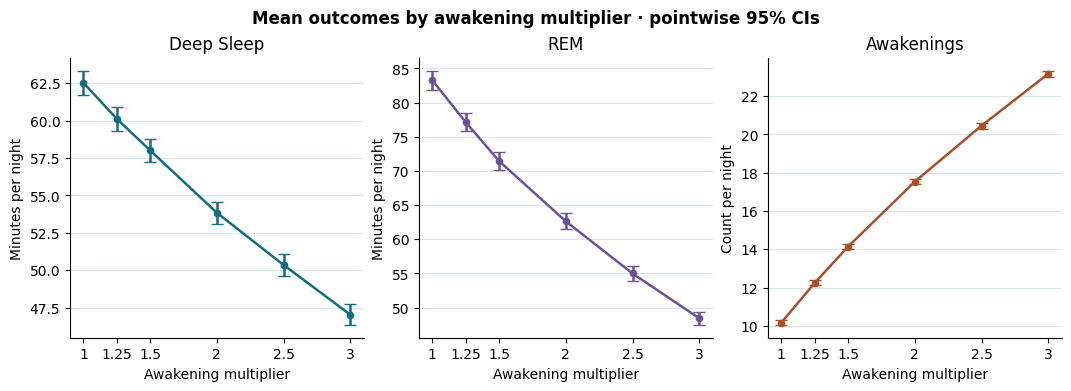

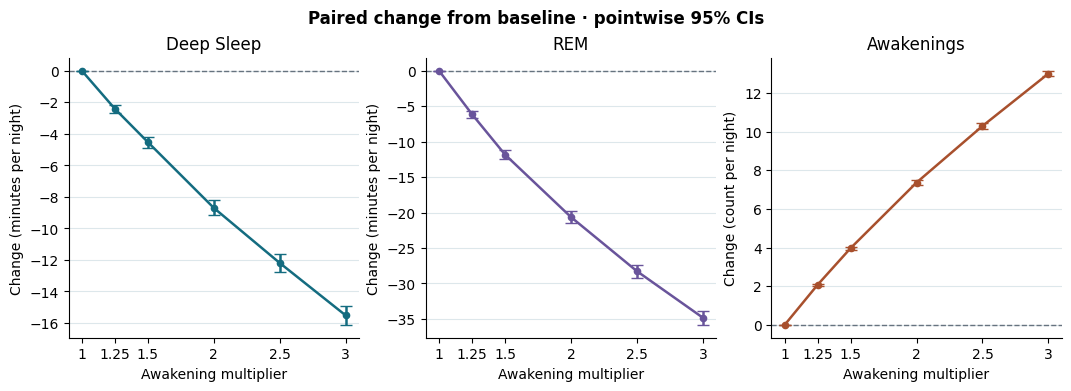

In [13]:
def x5_plot_intervals(means, lower, upper, title, paired=False):
    fig, axes = plt.subplots(1, 3, figsize=(10.6, 3.8), layout="constrained")
    panels = (
        ("Deep Sleep", "Minutes per night", "#146C80"),
        ("REM", "Minutes per night", "#69549B"),
        ("Awakenings", "Count per night", "#A8502D"),
    )
    for column, (ax, (label, unit, color)) in enumerate(zip(axes, panels)):
        if paired:
            ax.axhline(0, color="#66737F", linestyle="--", linewidth=1)
        values = means[:, column]
        errors = np.vstack((values - lower[:, column], upper[:, column] - values))
        ax.errorbar(x5_multipliers, values, yerr=errors, fmt="o-", capsize=4, color=color,
                    linewidth=1.8, markersize=4.5)
        ax.set_xticks(x5_multipliers, [f"{m:g}" for m in x5_multipliers])
        ax.set(title=label, xlabel="Awakening multiplier", ylabel=unit if not paired else f"Change ({unit.lower()})")
        ax.grid(axis="y", color="#DDE7EB", linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
    fig.suptitle(title, fontweight="semibold")
    return fig


x5_means_figure = x5_plot_intervals(
    x5_means, x5_lower, x5_upper, "Mean outcomes by awakening multiplier · pointwise 95% CIs"
)
plt.show()
x5_paired_figure = x5_plot_intervals(
    x5_changes, x5_change_lower, x5_change_upper, "Paired change from baseline · pointwise 95% CIs", paired=True
)
plt.show()

From multiplier 1 to 3, the mean paired change was **−15.5195 minutes of Deep Sleep**, **−34.8402 minutes of REM**, and **+13.0030 awakenings per night**. REM declined more than Deep Sleep at every tested setting above baseline. Awakening counts increased at each tested setting and are measured in counts per night.

Every non-baseline paired 95% interval excludes zero for its own comparison. These are pointwise intervals, so they do not provide simultaneous coverage over the entire sweep. The interval widths reflect Monte Carlo uncertainty under the fitted model. The results do not measure uncertainty in the fitted transition probabilities or establish real-world effects of increased awakenings.

### What the simulation found

Across 10,000 paired eight-hour nights, doubling the probability of moving from a sleep stage to Wake reduced average Deep Sleep by **8.574 minutes** (95% paired confidence interval **−8.783 to −8.365 minutes**) and REM by **20.829 minutes** (**−21.192 to −20.465 minutes**). Mean awakenings increased by **7.351 per night** (**7.300 to 7.402 awakenings per night**). All differences are multiplier 2 minus baseline. These intervals describe Monte Carlo uncertainty for the fitted model. The comparison represents a hypothetical change in the model.

### Model limitations

The model uses the same transition probabilities throughout the night. It was fitted to a small convenience subset, and pooling gives more weight to recordings with more valid transitions. The first and last scored sleep epochs only approximate the window boundaries. The chosen padding affects starting stages and Wake counts, and missing epochs interrupt observed transitions.

Held-out validation checked individual transitions. For example, the probability of staying in REM for another epoch was 2.21 percentage points lower in the held-out recordings than in training. A next step would be to check whole-night stage durations and awakening counts using the same window and metric definitions.

### Web demo reference check

The default demo uses the fitted baseline (multiplier 1) for one eight-hour night. A complete run should display **960 epochs**, each lasting 30 seconds. The demo draws a new random sequence on each run, so its Deep Sleep, REM, and awakening totals vary. The means and confidence intervals in Section 5 summarize 10,000 paired simulations.

1. B. Kemp, *Sleep-EDF Database Expanded*, v1.0.0, PhysioNet. [Dataset and annotation documentation](https://physionet.org/content/sleep-edfx/1.0.0/). DOI: 10.13026/C2X676. [ODC Attribution v1.0 licence](https://physionet.org/content/sleep-edfx/view-license/1.0.0/).
2. B. Kemp, A. H. Zwinderman, B. Tuk, H. A. C. Kamphuisen, and J. J. L. Oberyé, “Analysis of a sleep-dependent neuronal feedback loop: the slow-wave microcontinuity of the EEG,” *IEEE Transactions on Biomedical Engineering*, vol. 47, no. 9, pp. 1185–1194, 2000. [Publisher record](https://ieeexplore.ieee.org/document/867928/).
3. MNE-Python contributors, “Sleep stage classification from polysomnography (PSG) data.” [MNE-Python tutorial](https://mne.tools/stable/auto_tutorials/clinical/60_sleep.html#extract-30s-events-from-annotations).